Проверка

In [4]:
import sys

print(sys.executable)

/usr/local/bin/python3.11


Библиотеки

In [5]:
import pandas as pd
import pyarrow
import pyarrow.fs
import boto3
import matplotlib
import seaborn
import pyarrow.dataset as ds
import matplotlib.pyplot as plt
import os
from urllib.parse import urlparse
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv())

False

Подключение к garage

In [3]:
garage = boto3.client(
    "s3",
    aws_access_key_id=os.getenv("KEY"),
    aws_secret_access_key=os.getenv("SECRET"),
    endpoint_url=os.getenv("S3_ENDPOINT", "http://localhost:3900"),
    region_name="garage"
)

print("Buckets:")

response = garage.list_buckets()

for bucket in response["Buckets"]:
    print("-", bucket["Name"])

Buckets:
- clickstream-analytics
- clickstream-raw


Загрузка паркетов

Чтение паркетов


In [50]:
endpoint = urlparse(os.getenv("S3_ENDPOINT", "http://localhost:3900"))
garage_fs = pyarrow.fs.S3FileSystem(
    access_key=os.environ["KEY"],
    secret_key=os.environ["SECRET"],
    endpoint_override=endpoint.netloc,
    scheme=endpoint.scheme,
    region=os.getenv("S3_REGION", "garage"),
    force_virtual_addressing=False
)

columns = [
    "session_id",
    "session_start",
    "platform",
    "device_type",
    "operating_system",
    "browser",
    "had_search",
    "session_depth",
    "session_duration_seconds",
    "session_hour",
    "session_weekday",
    "engaged_session"
]

parquet_dataset = ds.dataset(
    "clickstream-analytics/curated/sessions",
    filesystem=garage_fs,
    format="parquet",
    partitioning="hive"
)
df = parquet_dataset.to_table(columns=columns).to_pandas()
df.head()


,session_id,session_start,platform,device_type,operating_system,browser,had_search,session_depth,session_duration_seconds,session_hour,session_weekday,engaged_session
0,001b1c05-06f4-477a-9c07-1d50c19783af,2023-01-01 10:57:46,Walmart,desktop,ios,chrome,True,3,108,10,1,0
1,00b5461b-2274-4c25-8b29-e8e97bf67fc4,2023-01-01 21:46:21,Flipkart,desktop,windows,chrome,False,3,103,21,1,0
2,00d8a5d0-0449-44c4-8df2-1166ba3b0700,2023-01-01 12:00:44,eBay,desktop,ios,safari,False,3,100,12,1,0
3,02b4eb79-93aa-4dba-9682-d07ebdc873ae,2023-01-01 20:38:10,Amazon,mobile,android,chrome,True,3,92,20,1,0
4,032096e5-d13c-4738-a103-c52350ddc199,2023-01-01 12:56:22,eBay,mobile,windows,chrome,False,2,59,12,1,0


Выбор необходимых признаков

In [51]:
columns = [
    "session_id",
    "session_start",
    "platform",
    "device_type",
    "operating_system",
    "browser",
    "had_search",
    "session_depth",
    "session_duration_seconds",
    "session_hour",
    "session_weekday",
    "engaged_session"
]

df = df[columns]

print("Количество сессий:", len(df))
print("Количество колонок:", len(df.columns))

df.head()

Количество сессий: 5772828
Количество колонок: 12


,session_id,session_start,platform,device_type,operating_system,browser,had_search,session_depth,session_duration_seconds,session_hour,session_weekday,engaged_session
0,001b1c05-06f4-477a-9c07-1d50c19783af,2023-01-01 10:57:46,Walmart,desktop,ios,chrome,True,3,108,10,1,0
1,00b5461b-2274-4c25-8b29-e8e97bf67fc4,2023-01-01 21:46:21,Flipkart,desktop,windows,chrome,False,3,103,21,1,0
2,00d8a5d0-0449-44c4-8df2-1166ba3b0700,2023-01-01 12:00:44,eBay,desktop,ios,safari,False,3,100,12,1,0
3,02b4eb79-93aa-4dba-9682-d07ebdc873ae,2023-01-01 20:38:10,Amazon,mobile,android,chrome,True,3,92,20,1,0
4,032096e5-d13c-4738-a103-c52350ddc199,2023-01-01 12:56:22,eBay,mobile,windows,chrome,False,2,59,12,1,0


Общая информация о дф

In [52]:
df.shape

(5772828, 12)

In [53]:
pd.set_option("display.float_format", "{:,.2f}".format)

In [54]:
df.describe()

,session_start,session_depth,session_duration_seconds,session_hour,session_weekday,engaged_session
count,5772828,"5,772,828.00","5,772,828.00","5,772,828.00","5,772,828.00","5,772,828.00"
mean,2024-01-07 05:54:20.969971712,2.78,129.27,14.00,3.99,0.03
min,2023-01-01 06:00:05,1.00,6.00,6.00,1.00,0.00
25%,2023-07-08 10:41:12,3.00,85.00,10.00,2.00,0.00
50%,2023-12-31 22:02:51.500000,3.00,112.00,14.00,4.00,0.00
75%,2024-07-07 13:40:29,3.00,155.00,18.00,6.00,0.00
max,2024-12-31 22:59:59,4.00,"1,098.00",22.00,7.00,1.00
std,NaN,0.47,65.10,4.90,2.07,0.16


In [55]:
print(f"Всего сессий: {len(df):,}")
print(
    f"Период: "
    f"{df['session_start'].min()} — "
    f"{df['session_start'].max()}"
)

print(
    f"\nСредняя глубина: "
    f"{df['session_depth'].mean():.2f}"
)

print(
    f"Средняя длительность: "
    f"{df['session_duration_seconds'].mean():.2f} сек"
)

print(
    f"Доля вовлечённых сессий: "
    f"{df['engaged_session'].mean() * 100:.2f}%"
)

Всего сессий: 5,772,828
Период: 2023-01-01 06:00:05 — 2024-12-31 22:59:59

Средняя глубина: 2.78
Средняя длительность: 129.27 сек
Доля вовлечённых сессий: 2.57%


Аналитический запрос 1

* Влияет ли поиск на глубину и длительность сессии? 

Средняя глубина сессии (с поиском/без поиска)

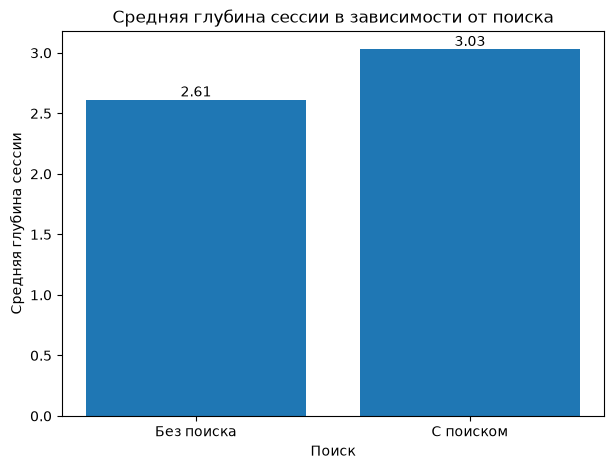

In [56]:
search_depth = (
    df.groupby("had_search")["session_depth"]
    .mean()
    .reset_index()
)

search_depth["search"] = search_depth["had_search"].map({
    False: "Без поиска",
    True: "С поиском"
})

plt.figure(figsize=(7, 5))

bars = plt.bar(
    search_depth["search"],
    search_depth["session_depth"]
)

plt.title("Средняя глубина сессии в зависимости от поиска")
plt.xlabel("Поиск")
plt.ylabel("Средняя глубина сессии")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

plt.show()

Средняя длина сессии (с поиском / без поиска)

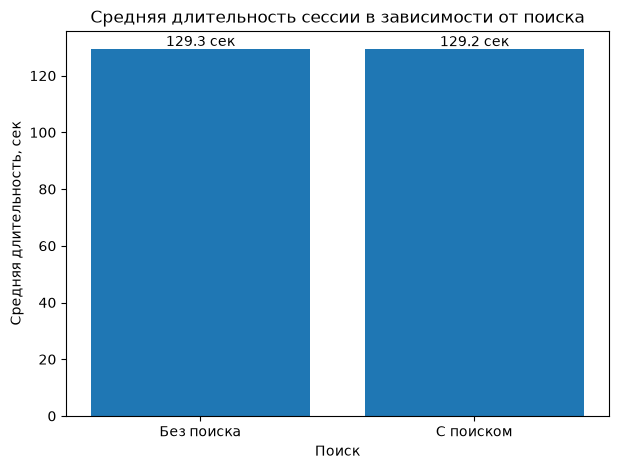

In [57]:
search_duration = (
    df.groupby("had_search")["session_duration_seconds"]
    .mean()
    .reset_index()
)

search_duration["search"] = search_duration["had_search"].map({
    False: "Без поиска",
    True: "С поиском"
})

min_value = search_duration["session_duration_seconds"].min()
max_value = search_duration["session_duration_seconds"].max()

padding = (max_value - min_value) * 0.5

plt.figure(figsize=(7, 5))

bars = plt.bar(
    search_duration["search"],
    search_duration["session_duration_seconds"]
)

plt.title("Средняя длительность сессии в зависимости от поиска")
plt.xlabel("Поиск")
plt.ylabel("Средняя длительность, сек")


for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f} сек",
        ha="center",
        va="bottom"
    )

plt.show()

Аналитический запрос 2

* доля вовлеченных сессий по типу устройства

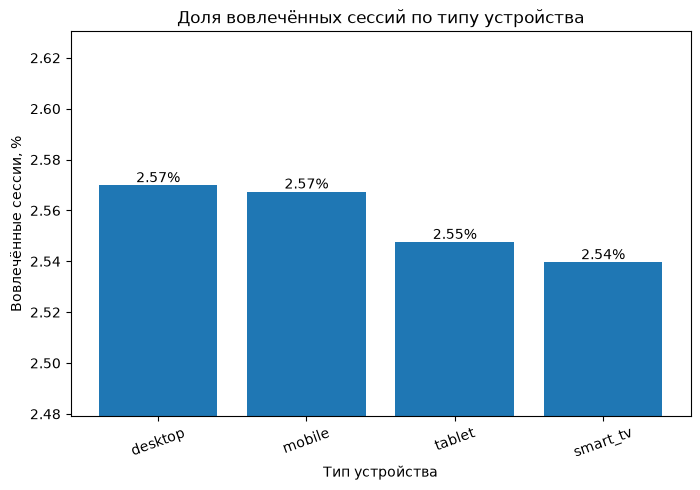

In [58]:
device_engagement = (
    df.groupby("device_type")["engaged_session"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

min_value = device_engagement.min()
max_value = device_engagement.max()

padding = max((max_value - min_value) * 2, 0.02)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    device_engagement.index,
    device_engagement.values
)

plt.title("Доля вовлечённых сессий по типу устройства")
plt.xlabel("Тип устройства")
plt.ylabel("Вовлечённые сессии, %")

plt.ylim(
    min_value - padding,
    max_value + padding
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}%",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=20)

plt.show()

Аналитический запрос 3

* Средняя длительность сессии по браузерам

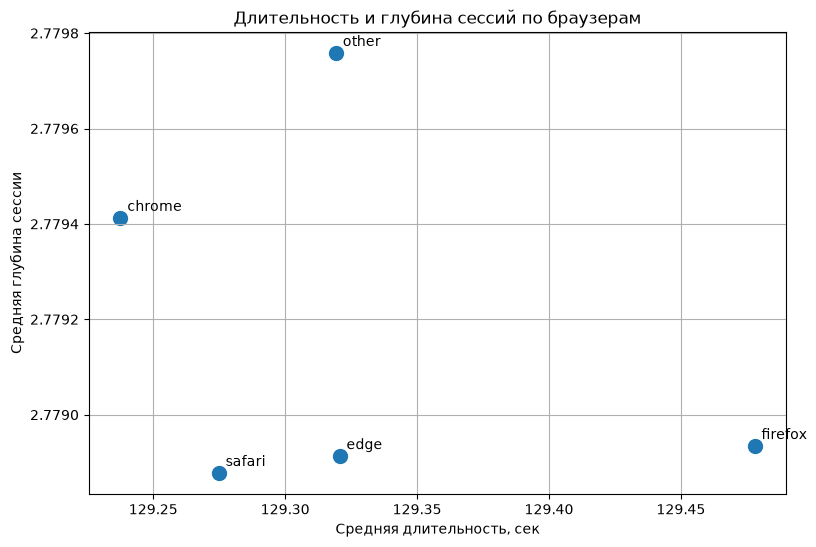

In [59]:
browser_stats = (
    df.groupby("browser")
    .agg(
        sessions=("session_id", "count"),
        avg_duration=("session_duration_seconds", "mean"),
        avg_depth=("session_depth", "mean")
    )
    .query("sessions >= 1000")
    .sort_values("avg_duration")
)

plt.figure(figsize=(9, 6))

plt.scatter(
    browser_stats["avg_duration"],
    browser_stats["avg_depth"],
    s=100
)

for browser, row in browser_stats.iterrows():
    plt.annotate(
        browser,
        (
            row["avg_duration"],
            row["avg_depth"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Длительность и глубина сессий по браузерам")
plt.xlabel("Средняя длительность, сек")
plt.ylabel("Средняя глубина сессии")

plt.grid(True)

plt.show()

Аналитический запрос 4

* средняя глубина сессии по часам суток

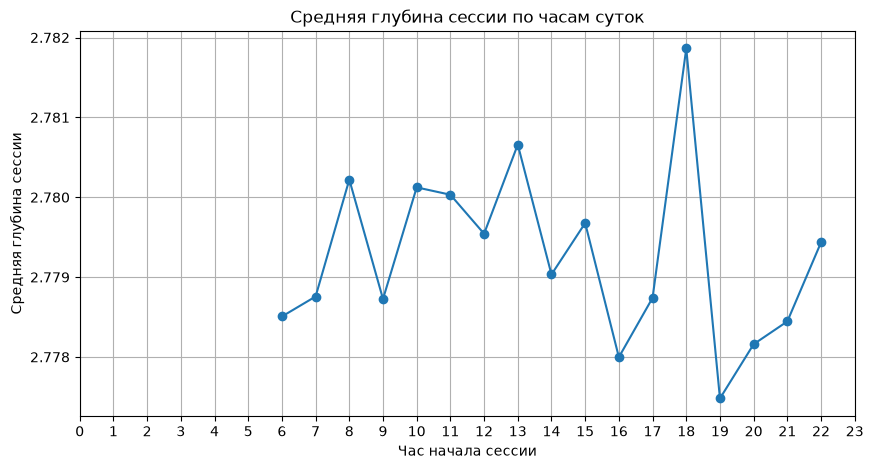

In [60]:
hour_stats = (
    df.groupby("session_hour")["session_depth"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

plt.plot(
    hour_stats["session_hour"],
    hour_stats["session_depth"],
    marker="o"
)

plt.title("Средняя глубина сессии по часам суток")
plt.xlabel("Час начала сессии")
plt.ylabel("Средняя глубина сессии")

plt.xticks(range(24))

plt.grid(True)

plt.show()

Вывод

1. Поиск заметно увеличивает глубину сессии, но практически не влияет на её длительность.
2. Устройства практически не различаются по уровню вовлечённости аудитории, хотя у desktop и mobile есть небольшое приемущество.
3. Браузеры также дают близкие показатели длительности и глубины сессий, но все же видно, что firefox дает более длинные и менее глубокие сессии, а chrome и other больше о глубине, чем о длительности.
4. Время посещения слабо связано с глубиной сессии, хотя видим небольшой час пик в 18:00, где глубина заметно подскакивает.

Общий вывод: наиболее заметная связь обнаружена между использованием поиска и глубиной сессии, остальные же факторы оказывают не такое значительное влияние.